# Part 8: ML that has to beat the volatility tilt, and a momentum blend

Notebook 02 found that the engineered feature set looked best, but a model-free "buy the most volatile quintile" rule earns almost the same return. So the honest question is:

> **Does any model add value beyond a volatility tilt?**

Two experiments answer it.

1. **Volatility-neutral target.** Stocks are bucketed into 5 volatility groups each month. The label becomes "beats the median of its *own* volatility bucket". A model trained on that label cannot earn its keep by recycling the volatility tilt.
2. **One-parameter blends.** `score = w * rank(ML) + (1 - w) * rank(other signal)`, where the other signal is 3-month momentum or volatility. One weight `w` is chosen by **walk-forward validation inside the training years** and then frozen.

**Rules that keep this honest**
- Inputs are 10 columns fixed **a priori**: 6 cluster averages (unsupervised) + 4 technical ranks (short and long price-vs-moving-average, MA cross, 6M volatility). No label-based selection, so walk-forward scores on 2005-2009 are not contaminated by later labels.
- Walk-forward: models are refit each January on snapshots up to the previous December and score that year. Hyperparameters for this walk-forward come from `GridSearchCV` on **pre-2005 data only**.
- Final models: `GridSearchCV` on all training data, fit once, frozen, applied to 2010-2018. The test period was already viewed in this project, so test numbers are a sanity check.
- Four model types (logistic, Gaussian naive Bayes, random forest, histogram gradient boosting) are combined by averaging their within-month ranks.
- Pure stock-picking skill is measured by the **bucket alpha**: inside each volatility bucket, the top-20% by score minus the bucket average (log returns). It is zero for a pure volatility tilt.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 40)

HERE = Path.cwd()
ROOT = HERE if (HERE / "mlfactor_long_only_train.csv").exists() else HERE.parent
FE = ROOT / "0_7_Feature_Engineering"
sys.path.insert(0, str(ROOT / "part0_data_and_benchmark"))
from pipeline import TARGET, return_month, performance          # shared course helpers

train = pd.read_csv(FE / "mlfactor_fe_train.csv", parse_dates=["date"])
test  = pd.read_csv(FE / "mlfactor_fe_test.csv",  parse_dates=["date"])

# Inputs fixed before looking at any result (see the markdown above)
CLEAN10 = ["cl5_avg", "cl1_avg", "cl2_avg", "cl4_avg", "cl6_avg", "cl3_avg",
           "ta_px_vs_ma_3m_rk", "ta_px_vs_ma_12m_rk", "ta_vol_6m_rk", "ta_ma_cross_rk"]
MOM, VOL = "ta_ma_3m_rk", "ta_vol_6m_rk"           # the two non-ML signals used for comparison/blends
need = CLEAN10 + [MOM, "fwd_log_ret", TARGET]
train = train.dropna(subset=need).reset_index(drop=True)   # complete cases: drops the first 12 train months' long windows
test  = test.dropna(subset=need).reset_index(drop=True)

def add_labels(d):
    """Volatility bucket (5 per month) and the two direction labels."""
    d["vb"] = d.groupby("date")[VOL].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False))
    d["y_raw"] = (d.fwd_log_ret > d.groupby("date").fwd_log_ret.transform("median")).astype(int)            # beats the month
    d["y_neu"] = (d.fwd_log_ret > d.groupby(["date", "vb"]).fwd_log_ret.transform("median")).astype(int)    # beats its own vol bucket
    return d
train, test = add_labels(train), add_labels(test)
print("train", train.shape, train.date.min().date(), "->", train.date.max().date())
print("test ", test.shape,  test.date.min().date(),  "->", test.date.max().date())

# Sanity: the neutral label should not lean on volatility, the raw label might.
for name, d in (("train", train),):
    print(name, "mean vol rank of winners  raw-label: %.3f   neutral-label: %.3f" %
          (d.loc[d.y_raw == 1, VOL].mean(), d.loc[d.y_neu == 1, VOL].mean()))

train (126066, 70) 2000-12-31 -> 2009-11-30
test  (127620, 70) 2009-12-31 -> 2018-11-30
train mean vol rank of winners  raw-label: 0.504   neutral-label: 0.500


## 1. Tools: strategies, bucket alpha, models, chronological folds

In [2]:
TOP_FRAC = 0.20

def rk(df, s):
    """Within-month percentile rank of a score (same 0-1 scale for every signal)."""
    return s.groupby(df["date"]).rank(pct=True, method="first")

def monthly(g):
    g = g.copy(); g.index = return_month(g.index); return g          # snapshot month -> month the return is earned

def ew_returns(df):
    return monthly(df.groupby("date")[TARGET].mean())

def top_returns(df, score):
    """Long-only: equal weight the top 20% by score each month."""
    return monthly(df[rk(df, score) > 1 - TOP_FRAC].groupby("date")[TARGET].mean())

def bucket_alpha(df, score):
    """Pure stock-picking skill: inside every vol bucket, top-20% mean minus bucket mean of log returns."""
    d = df[["date", "vb", "fwd_log_ret"]].copy()
    d["p"] = score.groupby([df["date"], df["vb"]]).rank(pct=True, method="first")
    top = d[d.p > 1 - TOP_FRAC].groupby(["date", "vb"]).fwd_log_ret.mean()
    allm = d.groupby(["date", "vb"]).fwd_log_ret.mean()
    return (top - allm).groupby("date").mean()

def alpha_summary(a):
    return pd.Series({"alpha_ann": a.mean() * 12, "alpha_t": a.mean() / a.std() * np.sqrt(len(a)), "alpha_hit": (a > 0).mean()})

def bucket_ic(df, score):
    """Mean monthly rank correlation of score with future return, ranks taken within vol buckets."""
    d = pd.DataFrame({"date": df["date"], "s": score.groupby([df["date"], df["vb"]]).rank(pct=True),
                      "r": df.groupby(["date", "vb"]).fwd_log_ret.rank(pct=True)})
    return d.groupby("date").apply(lambda g: g.s.corr(g.r)).mean()

MODELS = {
    "logistic": (LogisticRegression(max_iter=500), {"C": [0.01, 0.1, 1, 10]}),
    "naive_bayes": (GaussianNB(), {"var_smoothing": [1e-9, 1e-6, 1e-3]}),
    "random_forest": (RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=0),
                      {"max_depth": [3, 6], "min_samples_leaf": [200, 1000]}),
    "grad_boosting": (HistGradientBoostingClassifier(max_iter=150, early_stopping=False, random_state=0),
                      {"max_depth": [2, 3], "learning_rate": [0.03, 0.1]}),
}

def month_splits(df, n_folds):
    """Expanding-window folds by month: always train on earlier months, validate on the next block."""
    months = np.sort(df["date"].unique())
    edges = np.linspace(len(months) // 4, len(months), n_folds + 1).astype(int)
    return [(np.where(df["date"].isin(months[:a]))[0], np.where(df["date"].isin(months[a:b]))[0])
            for a, b in zip(edges[:-1], edges[1:])]

def tune(df, label, n_folds):
    """GridSearchCV (ROC-AUC) for every model on df -> {model: fitted GridSearchCV}."""
    splits = month_splits(df, n_folds)
    out = {}
    for name, (est, grid) in MODELS.items():
        out[name] = GridSearchCV(clone(est), grid, cv=splits, scoring="roc_auc", n_jobs=1, refit=True).fit(df[CLEAN10], df[label])
    return out

## 2. Tuning with `GridSearchCV` (train only)

Two sets of searches per label: one on **pre-2005 snapshots** (parameters used inside the walk-forward) and one on **all training snapshots** (parameters for the frozen final models).

In [3]:
WF_START = pd.Timestamp("2005-01-31")          # walk-forward scores January 2005 onward
pre = train[train.date < WF_START].reset_index(drop=True)

searches = {}
for label in ("y_raw", "y_neu"):
    searches[("wf", label)]    = tune(pre,   label, n_folds=4)     # params for walk-forward (no 2005+ information)
    searches[("final", label)] = tune(train, label, n_folds=5)     # params for the frozen final models
    for kind in ("wf", "final"):
        print(label, kind, {m: (round(g.best_score_, 4), g.best_params_) for m, g in searches[(kind, label)].items()})

y_raw wf {'logistic': (0.5179, {'C': 10}), 'naive_bayes': (0.5134, {'var_smoothing': 0.001}), 'random_forest': (0.5209, {'max_depth': 6, 'min_samples_leaf': 200}), 'grad_boosting': (0.5245, {'learning_rate': 0.1, 'max_depth': 3})}
y_raw final {'logistic': (0.5015, {'C': 10}), 'naive_bayes': (0.5029, {'var_smoothing': 1e-06}), 'random_forest': (0.5096, {'max_depth': 6, 'min_samples_leaf': 200}), 'grad_boosting': (0.5122, {'learning_rate': 0.1, 'max_depth': 3})}
y_neu wf {'logistic': (0.524, {'C': 0.1}), 'naive_bayes': (0.5256, {'var_smoothing': 1e-06}), 'random_forest': (0.5298, {'max_depth': 6, 'min_samples_leaf': 200}), 'grad_boosting': (0.5292, {'learning_rate': 0.03, 'max_depth': 3})}
y_neu final {'logistic': (0.5025, {'C': 0.01}), 'naive_bayes': (0.5062, {'var_smoothing': 1e-09}), 'random_forest': (0.5119, {'max_depth': 6, 'min_samples_leaf': 200}), 'grad_boosting': (0.5138, {'learning_rate': 0.1, 'max_depth': 3})}


## 3. Scores: walk-forward on training years, frozen models on test

Walk-forward: for each year 2005-2009, fit on snapshots up to the previous December and score that year's snapshots. A snapshot's label is earned the following month, so a fit that ends in December only uses returns already realized when the next January decision is made. Each model's probability is turned into a within-month rank and the four ranks are averaged (`ens`).

In [4]:
def fitted(label, kind, name, data):
    """Unfitted clone with the searched parameters for this label/kind/model."""
    est = clone(MODELS[name][0]); est.set_params(**searches[(kind, label)][name].best_params_)
    return est

def ensemble(df, probs):
    """Average of the four models' within-month ranks."""
    return pd.concat([rk(df, probs[n]) for n in MODELS], axis=1).mean(axis=1)

oos = train[train.date >= WF_START].copy()
oos_probs = {l: {n: pd.Series(np.nan, index=oos.index) for n in MODELS} for l in ("y_raw", "y_neu")}
for year in range(2005, 2010):
    fit_rows = train[train.date <= f"{year - 1}-12-31"]
    score_rows = oos[oos.date.dt.year == year]
    for label in oos_probs:
        for n in MODELS:
            m = fitted(label, "wf", n, fit_rows).fit(fit_rows[CLEAN10], fit_rows[label])
            oos_probs[label][n].loc[score_rows.index] = m.predict_proba(score_rows[CLEAN10])[:, 1]
    print("walk-forward year", year, "fit rows", len(fit_rows))

test_probs = {l: {n: pd.Series(searches[("final", l)][n].best_estimator_.predict_proba(test[CLEAN10])[:, 1], index=test.index)
                  for n in MODELS} for l in ("y_raw", "y_neu")}

S = {}   # S[window][signal] -> score Series aligned to that window's rows
S["oos_2005_2009"] = {"naive_ML": ensemble(oos, oos_probs["y_raw"]), "neutral_ML": ensemble(oos, oos_probs["y_neu"]),
                      "momentum": oos[MOM], "volatility": oos[VOL]}
S["test_2010_2018"] = {"naive_ML": ensemble(test, test_probs["y_raw"]), "neutral_ML": ensemble(test, test_probs["y_neu"]),
                       "momentum": test[MOM], "volatility": test[VOL]}
WIN = {"oos_2005_2009": oos, "test_2010_2018": test}

walk-forward year 2005 fit rows 55758
walk-forward year 2006 fit rows 70062
walk-forward year 2007 fit rows 84393
walk-forward year 2008 fit rows 98694
walk-forward year 2009 fit rows 112969


## 4. Per-model check: do the models rank anything once volatility is neutralized?

In [5]:
rows = []
for label, tag in (("y_raw", "raw label"), ("y_neu", "vol-neutral label")):
    for n in MODELS:
        po, pt = oos_probs[label][n], test_probs[label][n]
        rows.append({"label": tag, "model": n, "cv_auc_final": searches[("final", label)][n].best_score_,
                     "oos_auc": roc_auc_score(oos[label], po), "test_auc": roc_auc_score(test[label], pt),
                     "oos_bucket_IC": bucket_ic(oos, po), "test_bucket_IC": bucket_ic(test, pt),
                     "params_final": json.dumps(searches[("final", label)][n].best_params_)})
model_table = pd.DataFrame(rows)
model_table.drop(columns="params_final").round(4)

,label,model,cv_auc_final,oos_auc,test_auc,oos_bucket_IC,test_bucket_IC
0,raw label,logistic,0.5015,0.4913,0.5018,-0.0132,0.0131
1,raw label,naive_bayes,0.5029,0.4933,0.5011,-0.0012,0.0098
2,raw label,random_forest,0.5096,0.5007,0.5033,0.0086,0.0173
3,raw label,grad_boosting,0.5122,0.5066,0.5043,0.0159,0.0152
4,vol-neutral label,logistic,0.5025,0.4913,0.5052,-0.0117,0.0112
5,vol-neutral label,naive_bayes,0.5062,0.4949,0.5042,-0.0001,0.0096
6,vol-neutral label,random_forest,0.5119,0.5019,0.5069,0.0090,0.0160
7,vol-neutral label,grad_boosting,0.5138,0.5042,0.5069,0.0132,0.0155


## 5. Choosing the blend weight (walk-forward years only)

`w` is the share given to the ML rank. It is chosen by the **Sharpe ratio of the top-20% book over 2005-2009 walk-forward scores**. The test curve is plotted for display only and is never used to choose.

In [6]:
W = [0.0, 0.25, 0.5, 0.75, 1.0]
def blend(win, other, w):
    s = S[win]
    return w * rk(WIN[win], s["neutral_ML"]) + (1 - w) * rk(WIN[win], s[other])

curve = []
for other in ("momentum", "volatility"):
    for w in W:
        curve.append({"other": other, "w_ml": w,
                      "oos_sharpe": performance(top_returns(oos, blend("oos_2005_2009", other, w))).sharpe,
                      "test_sharpe": performance(top_returns(test, blend("test_2010_2018", other, w))).sharpe})
curve = pd.DataFrame(curve)
CHOSEN = {o: float(g.loc[g.oos_sharpe.idxmax(), "w_ml"]) for o, g in curve.groupby("other")}
print("weights chosen on 2005-2009 walk-forward Sharpe:", CHOSEN)
curve.round(3)

weights chosen on 2005-2009 walk-forward Sharpe: {'momentum': 0.5, 'volatility': 0.0}


,other,w_ml,oos_sharpe,test_sharpe
0,momentum,0.00,0.583,0.864
1,momentum,0.25,0.572,0.965
2,momentum,0.50,0.631,1.011
3,momentum,0.75,0.578,0.933
4,momentum,1.00,0.555,0.935
5,volatility,0.00,0.701,0.843
6,volatility,0.25,0.685,0.887
7,volatility,0.50,0.520,0.903
8,volatility,0.75,0.474,0.877
9,volatility,1.00,0.555,0.935


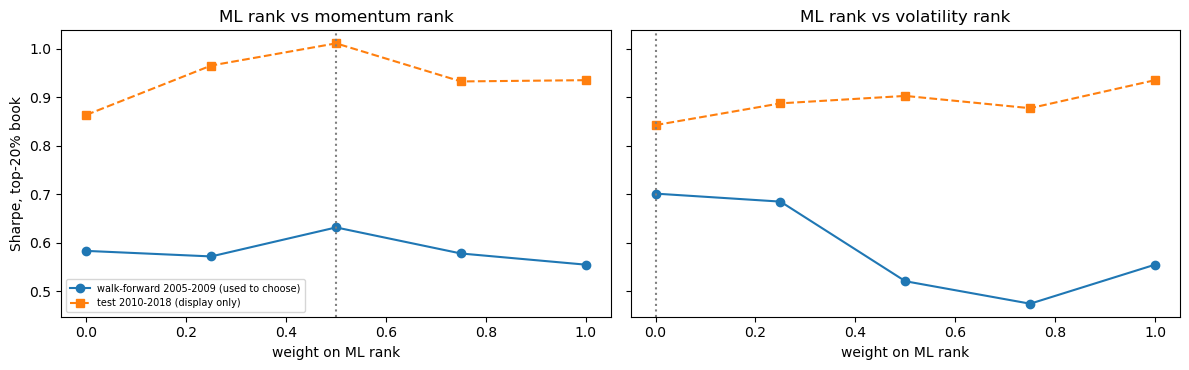

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, other in zip(ax, ("momentum", "volatility")):
    g = curve[curve.other == other]
    a.plot(g.w_ml, g.oos_sharpe, "o-", label="walk-forward 2005-2009 (used to choose)")
    a.plot(g.w_ml, g.test_sharpe, "s--", label="test 2010-2018 (display only)")
    a.axvline(CHOSEN[other], c="gray", ls=":"); a.set_title(f"ML rank vs {other} rank"); a.set_xlabel("weight on ML rank")
ax[0].set_ylabel("Sharpe, top-20% book"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 6. All strategies, both windows

Non-ML: equal weight, top-volatility quintile, top-momentum quintile. ML: the naive ensemble, the vol-neutral ensemble, and the two blends with the chosen weights.

In [8]:
def strategies(win):
    d, s = WIN[win], S[win]
    sig = {"Top volatility quintile (no ML)": s["volatility"], "Top momentum quintile (no ML)": s["momentum"],
           "Naive ML ensemble": s["naive_ML"], "Vol-neutral ML ensemble": s["neutral_ML"],
           f"Vol-neutral ML + momentum (w={CHOSEN['momentum']:.2f})": blend(win, "momentum", CHOSEN["momentum"]),
           f"Vol-neutral ML + volatility (w={CHOSEN['volatility']:.2f})": blend(win, "volatility", CHOSEN["volatility"])}
    out = {"Equal weight": (ew_returns(d), None)}
    for name, score in sig.items():
        out[name] = (top_returns(d, score), bucket_alpha(d, score))
    return out

rows, paths = [], {}
for win in WIN:
    for name, (ret, alpha) in strategies(win).items():
        p = performance(ret)
        a = alpha_summary(alpha) if alpha is not None else pd.Series({"alpha_ann": np.nan, "alpha_t": np.nan, "alpha_hit": np.nan})
        rows.append({"window": win, "strategy": name, "months": int(p.months), "cagr": p.cagr,
                     "annual_log_growth": p.annualized_log_growth, "volatility": p.annualized_volatility,
                     "sharpe": p.sharpe, "max_drawdown": p.max_drawdown, **a.to_dict()})
        paths[(win, name)] = ret
results = pd.DataFrame(rows)
for win in WIN:
    print(win); display(results[results.window == win].drop(columns="window").set_index("strategy").round(3))

oos_2005_2009


,months,cagr,annual_log_growth,volatility,sharpe,max_drawdown,alpha_ann,alpha_t,alpha_hit
strategy,,,,,,,,,
Equal weight,59,0.085,0.082,0.233,0.469,-0.495,NaN,NaN,NaN
Top volatility quintile (no ML),59,0.217,0.196,0.374,0.701,-0.550,0.022,1.077,0.593
Top momentum quintile (no ML),59,0.112,0.106,0.224,0.583,-0.462,-0.017,-0.489,0.441
Naive ML ensemble,59,0.119,0.112,0.306,0.520,-0.561,0.031,0.983,0.559
Vol-neutral ML ensemble,59,0.130,0.123,0.303,0.555,-0.526,0.030,0.942,0.542
Vol-neutral ML + momentum (w=0.50),59,0.128,0.121,0.236,0.631,-0.481,0.018,1.098,0.627
Vol-neutral ML + volatility (w=0.00),59,0.217,0.196,0.374,0.701,-0.550,0.022,1.077,0.593


test_2010_2018


,months,cagr,annual_log_growth,volatility,sharpe,max_drawdown,alpha_ann,alpha_t,alpha_hit
strategy,,,,,,,,,
Equal weight,108,0.131,0.123,0.156,0.868,-0.207,NaN,NaN,NaN
Top volatility quintile (no ML),108,0.184,0.169,0.233,0.843,-0.270,0.009,0.861,0.565
Top momentum quintile (no ML),108,0.130,0.123,0.157,0.864,-0.186,-0.009,-0.602,0.472
Naive ML ensemble,108,0.173,0.160,0.195,0.918,-0.224,0.022,1.861,0.556
Vol-neutral ML ensemble,108,0.167,0.155,0.184,0.935,-0.225,0.022,1.936,0.583
Vol-neutral ML + momentum (w=0.50),108,0.160,0.149,0.160,1.011,-0.168,0.018,1.596,0.546
Vol-neutral ML + volatility (w=0.00),108,0.184,0.169,0.233,0.843,-0.270,0.009,0.861,0.565


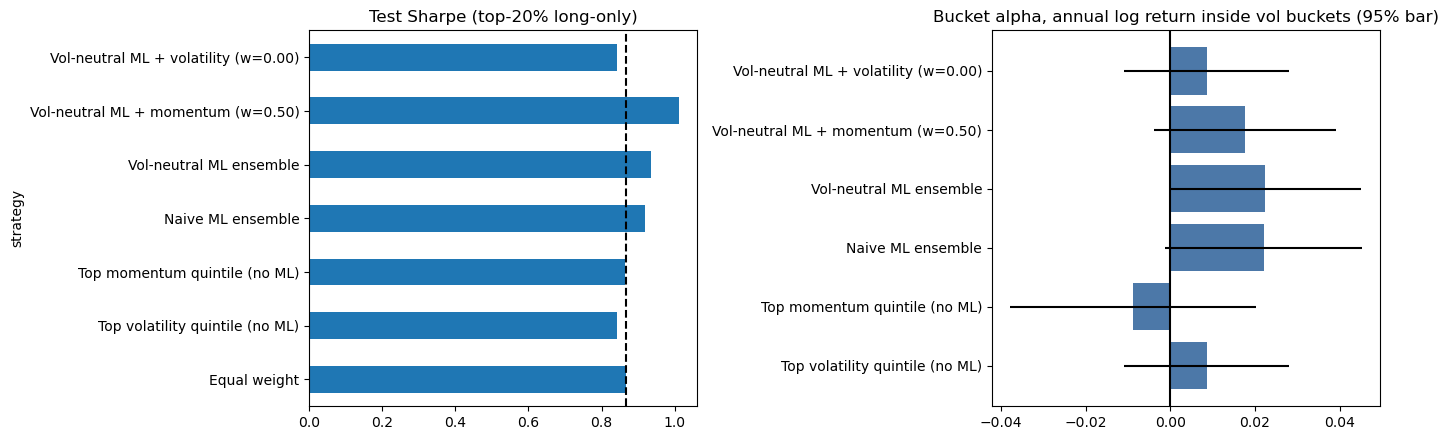

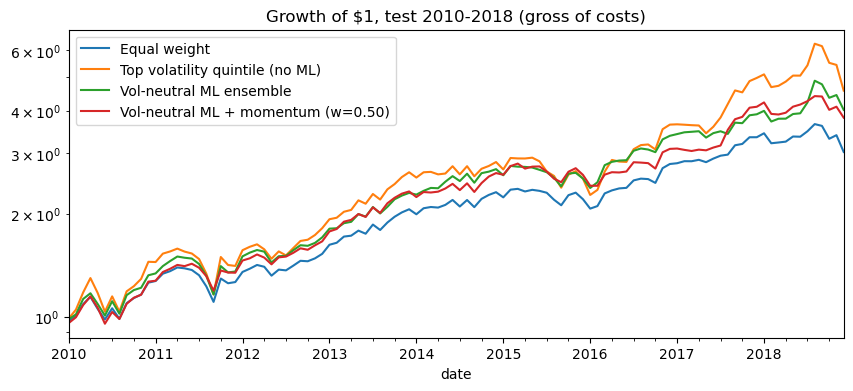

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
t = results[results.window == "test_2010_2018"].set_index("strategy")
t["sharpe"].plot(kind="barh", ax=ax[0], title="Test Sharpe (top-20% long-only)"); ax[0].axvline(t.loc["Equal weight", "sharpe"], c="k", ls="--")
a = t.dropna(subset=["alpha_ann"])
ax[1].barh(a.index, a.alpha_ann, xerr=a.alpha_ann / a.alpha_t.replace(0, np.nan) * 1.96, color="#4c78a8")
ax[1].axvline(0, c="k"); ax[1].set_title("Bucket alpha, annual log return inside vol buckets (95% bar)")
plt.tight_layout(); plt.show()

g = pd.DataFrame({k[1]: (1 + v).cumprod() for k, v in paths.items() if k[0] == "test_2010_2018"})
g[["Equal weight", "Top volatility quintile (no ML)", "Vol-neutral ML ensemble"] + [c for c in g if "momentum (w" in c]].plot(
    figsize=(10, 4), logy=True, title="Growth of $1, test 2010-2018 (gross of costs)"); plt.show()

In [10]:
# Save everything the graded notebook needs to READ without refitting.
results.to_csv(FE / "part8_strategy_results.csv", index=False)
model_table.to_csv(FE / "part8_model_table.csv", index=False)
curve.to_csv(FE / "part8_blend_curve.csv", index=False)
(FE / "part8_meta.json").write_text(json.dumps({
    "features": CLEAN10, "momentum_signal": MOM, "volatility_signal": VOL, "vol_buckets": 5, "top_fraction": TOP_FRAC,
    "chosen_weights": CHOSEN, "weight_grid": W, "walk_forward": "annual refit, snapshots through prior December, 2005-2009",
    "tuning": "GridSearchCV roc_auc; walk-forward params from pre-2005 data, final params from all training data",
    "test_previously_viewed": True, "test_used_for_choices": False,
    "train_rows": len(train), "test_rows": len(test)}, indent=2))
print("saved part8_* files to", FE)

saved part8_* files to /home/sweethoney/Documents/MFM/Semester5_Sept_Dec_2026/DataScience/11_mlfactor_long_only_project_2026/0_7_Feature_Engineering


## 7. What the results say

**1. Neutralizing volatility barely changes the models.** AUCs stay at 0.50-0.507 with either label, in the walk-forward years and on test. The models still do not rank stocks well. That matches the formal engineering study.

**2. There is a small, not-significant stock-picking effect.** Inside volatility buckets, the vol-neutral ML ensemble's top 20% beats its bucket by about 2.2% a year on test (t = 1.9) and 3.0% a year in the walk-forward years (t = 0.9). The sign agrees in both windows, but neither clears a conventional bar, and this is one 108-month path with several strategies compared. Read it as "maybe a little", not as proof. The naive ensemble shows nearly the same alpha, so the vol-neutral label is not what creates it.

**3. The ML + momentum blend is the most useful result.** With the weight chosen on 2005-2009 (w = 0.5), the test book has a Sharpe of 1.01 against 0.87 for equal weight. CAGR is 16.0% against 13.1%, volatility is about the same (16.0% vs 15.6%), and max drawdown is shallower (-16.8% vs -20.7%). It does not simply load on volatility: the volatility-only rule has the same CAGR neighborhood but much higher volatility (23%) and a deeper drawdown (-27%). Caveats: the Sharpe differences between weights in 2005-2009 are small (0.56 to 0.63), the weight curve is not smooth, and the test window was already viewed.

**4. The ML + volatility blend is just the volatility rule.** Walk-forward picked w = 0 (2005-2009 rewarded volatility, which includes the 2009 rebound), so that row equals the top-volatility quintile. It also shows how fragile choosing a weight on five years is: on test, w = 0 is the worst weight.

**5. Gross of costs.** No transaction costs are deducted, and the top-20% books turn over a lot.

**Suggested use in the report:** present (1) the diagnosis that the first engineered gain was a volatility tilt, (2) the bucket-alpha test as the honest measure of model skill, and (3) the momentum blend as a modest, risk-adjusted improvement, with the caveats above.